# Olist Brezilya E-Ticaret Veri Seti – Keşifsel Veri Analizi (EDA) 

Bu notebook kapsamında:
- Veri setinin ilk keşfi yapılmıştır
- Veri kalitesi kontrolleri gerçekleştirilmiştir
- Veri temizleme ve dönüşüm adımları uygulanmıştır
- SQL ve Spark analizleri için hazır, analiz edilebilir bir veri seti oluşturulmuştur

# Data preparation

In [1]:
#Kütüphaneler indirildi
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
sns.set(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

In [2]:
import os
print(os.getcwd())

C:\Users\sinem\Desktop\WTECH_BigData_Project\notebooks


In [3]:
#veri setleri indirildi
customers = pd.read_csv("../data/customers.csv")
products = pd.read_csv("../data/products.csv", sep=";") 
sellers = pd.read_csv("../data/sellers.csv")
orders = pd.read_csv("../data/orders.csv")
order_items = pd.read_csv("../data/order_items.csv")
reviews = pd.read_csv("../data/reviews.csv")
geolocation = pd.read_csv("../data/geolocation.csv")
payments = pd.read_csv("../data/payments.csv")

In [4]:
# veri setlerini daha hızlı inceleyebilmek için bir fonksiyon oluşturuldu.
#bu fonksiyon ile head,shape,info gibi bilgilere tek seferde ulaşıyoruz.

def quick_overview(df, name):
    print(f"--- {name.upper()} ---")
    display(df.head(10))
    print(df.shape)
    df.info() 

## Analiz, görselleştirme ve feature engineering

In [5]:
quick_overview(customers,"customers")

--- CUSTOMERS ---


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG


(99441, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [6]:
customers.duplicated().sum()

0

99K müşterilik bir veri seti, eksik veri yok. Müşteriler farklı şehir ve eyaletlerden dağılım geniş. customer_id, customer_unique_id farkı önemli burada müşteri analizi için unique_id kullanılmalı çünkü customer_id her siparişte değişebilir.Şehir-eyalet bilgisi var , geolocation dataset ile join yapılabilir.

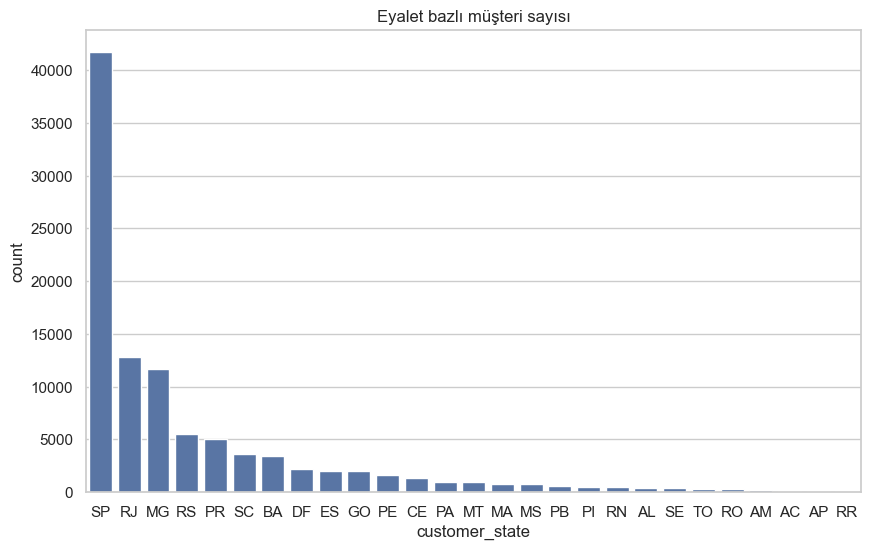

In [7]:
# 1. Eyalet bazlı müşteri sayısı
plt.figure(figsize=(10,6))
sns.countplot(data=customers, x='customer_state', order=customers['customer_state'].value_counts().index)
plt.title("Eyalet bazlı müşteri sayısı")
plt.show()


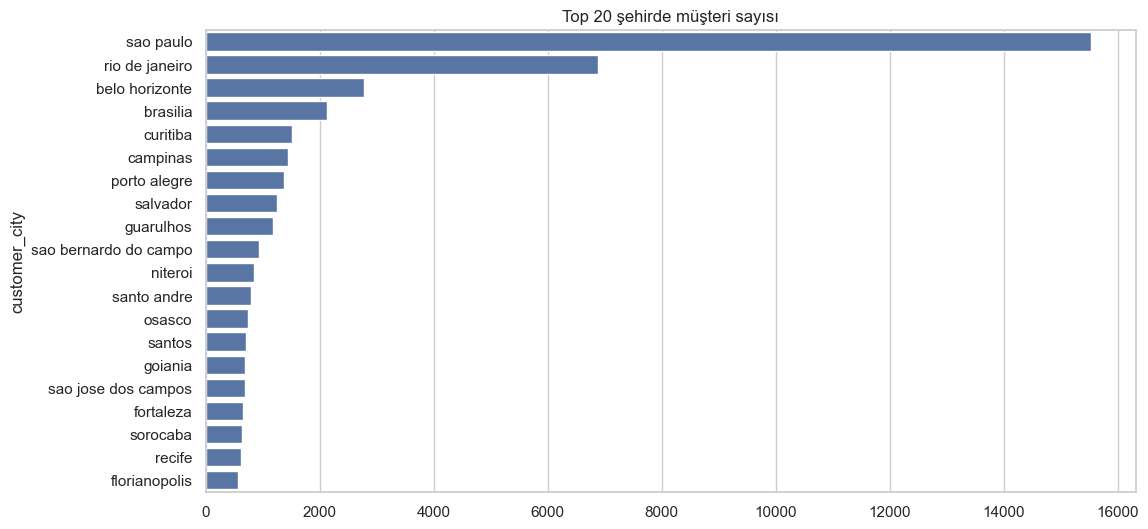

In [8]:
# 2. Şehir bazlı en fazla müşteri olan ilk 20 şehir
top_cities = customers['customer_city'].value_counts().head(20)
plt.figure(figsize=(12,6))
sns.barplot(x=top_cities.values, y=top_cities.index)
plt.title("Top 20 şehirde müşteri sayısı")
plt.show()

 Şehir bazında bakıldığında da Sao Paulo yine liderliğini koruyor,ancak ilk 5 şehirden sonra müşteri sayıları hızla düşerek birbirine yakın seviyelere geriliyor.
Müşteri kitlesinin çoğu sadece belli ana merkezlerden geliyor. Bu şehirlerdeki lojistik maliyetlerini düşürmek, toplam kârlılığı doğrudan artıracaktır.

In [9]:
quick_overview(orders,"orders")

--- ORDERS ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01 00:00:00
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaN,2017-05-09 00:00:00
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07 00:00:00
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-01-26 14:16:31,2017-02-02 14:08:10,2017-03-06 00:00:00
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23 00:00:00


(99441, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [10]:
orders.duplicated().sum()

0

Siparişler tahmini teslim tarihinden önce teslim edilmiş.Sipariş teslimi genelde 11 günden az.  eksik veriler var; order_approved_at, order_delivered_carrier_date,order_delivered_customer_date - Buralardaki eksiklikler iptal edilen ya da henüz teslim edilmemiş siparişlerle açıklanabilir. Daha önemli bir durum ise tarih verilerinin object olarak girilmiş olması , onları datetime'a çevirmeliyiz.   

In [11]:
#Tarih verileri,*datetime* formatına çevrildi.  
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])


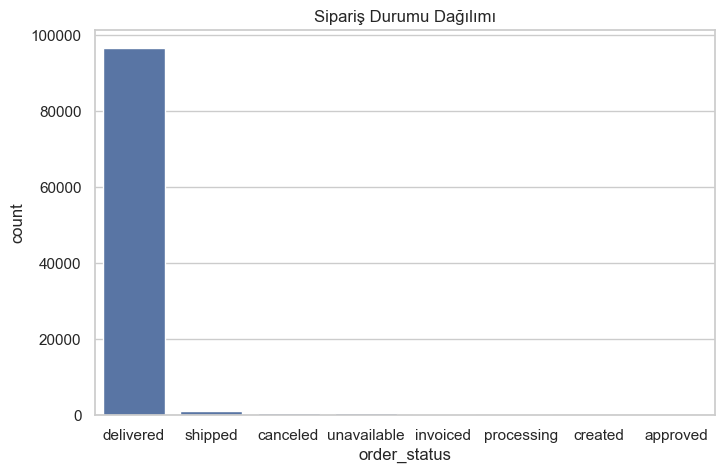

In [12]:
# Sipariş durumları dağılımı
plt.figure(figsize=(8,5))
sns.countplot(data=orders, x='order_status', order=orders['order_status'].value_counts().index)
plt.title("Sipariş Durumu Dağılımı")
plt.show()

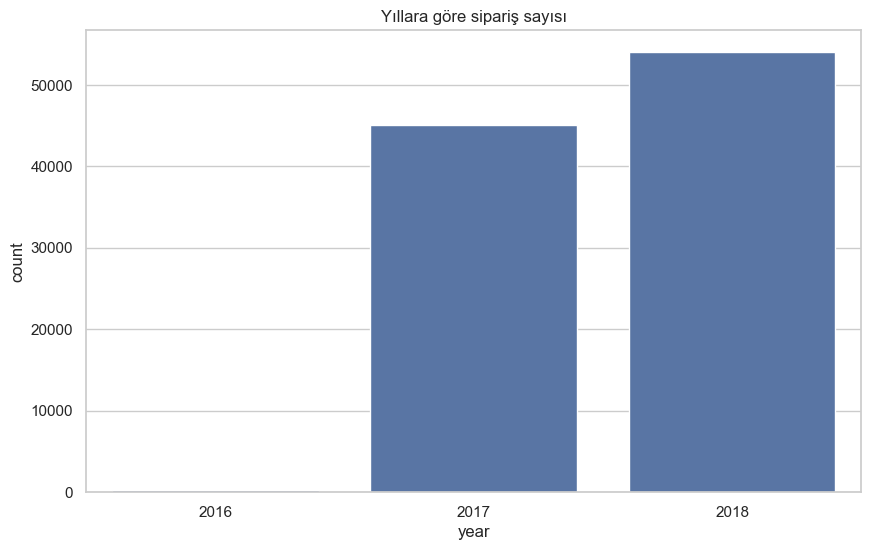

In [13]:
# Sipariş tarihine göre trend (yıllık)
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['year'] = orders['order_purchase_timestamp'].dt.year
plt.figure(figsize=(10,6))
sns.countplot(data=orders, x='year')
plt.title("Yıllara göre sipariş sayısı")
plt.show()

İşletme 2017'nin başından itibaren agresif bir büyüme sergilemiş. Özellikle 2017 son çeyreğinde (Kasım-Aralık) yaşanan sıçrama muhtemelen Black Friday ve yılbaşı indirimlerinden kaynaklanıyor.2018'in ortasından sonra yaşanan sert düşüş veri setinin o tarihte kesilmesinden kaynaklanıyor.

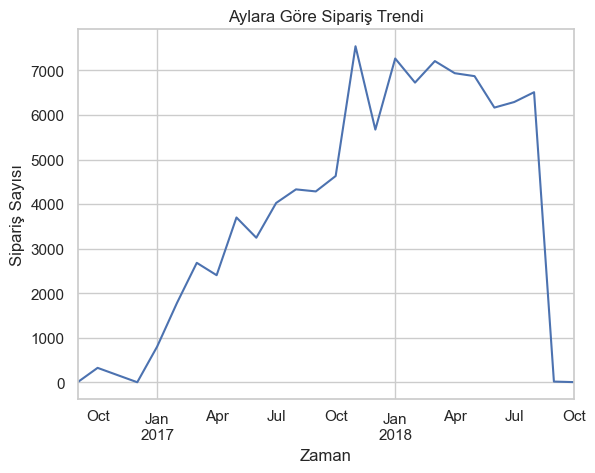

In [14]:
orders["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index().plot()
plt.title("Aylara Göre Sipariş Trendi")
plt.xlabel("Zaman")
plt.ylabel("Sipariş Sayısı")
plt.show()

In [15]:
orders['delay'] = (pd.to_datetime(orders['order_delivered_customer_date']) - pd.to_datetime(orders['order_estimated_delivery_date'])).dt.days

In [16]:
orders['delivery_time'] = (pd.to_datetime(orders['order_delivered_customer_date']) - pd.to_datetime(orders['order_purchase_timestamp'])).dt.days

In [17]:
# Sadece teslim edilenleri aldım (Analiz kalitesi için)
orders_delivered = orders[orders['order_status'] == 'delivered'].copy()

# Tarih dönüşümleri ve gün hesaplamaları
orders_delivered['order_purchase_timestamp'] = pd.to_datetime(orders_delivered['order_purchase_timestamp'])
orders_delivered['order_delivered_customer_date'] = pd.to_datetime(orders_delivered['order_delivered_customer_date'])
orders_delivered['order_estimated_delivery_date'] = pd.to_datetime(orders_delivered['order_estimated_delivery_date'])

# Ana Metrikler
orders_delivered['delivery_time'] = (orders_delivered['order_delivered_customer_date'] - orders_delivered['order_purchase_timestamp']).dt.days
orders_delivered['delay'] = (orders_delivered['order_delivered_customer_date'] - orders_delivered['order_estimated_delivery_date']).dt.days
orders_delivered['estimated_delivery_days'] = (orders_delivered['order_estimated_delivery_date'] - orders_delivered['order_purchase_timestamp']).dt.days

# Outlier temizliği 
orders_clean = orders_delivered[
    (orders_delivered["delay"] > -30) & 
    (orders_delivered["delay"] < 30)
].copy()

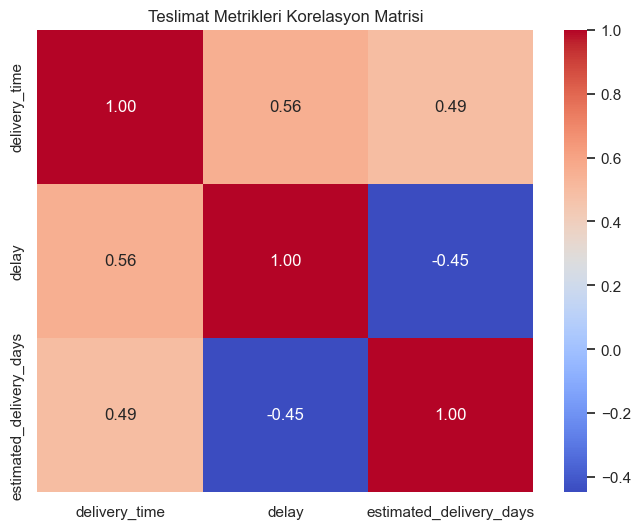

In [18]:
# Korelasyon analizi numeric - numeric verilerle yapılabilir ,
#ancak *order_estimated_delivery_date* datatype:datetime bu yüzden öncelikle onu numeric olarak değişmemiz gerekiyor.
# Sadece sayısal kolonları seçiyoruz
corr_data = orders_clean[["delivery_time", "delay", "estimated_delivery_days"]]
corr = corr_data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Teslimat Metrikleri Korelasyon Matrisi")
plt.show()

delivery_time ve delay arasındaki ilişki 0.56 ile orta-yuksek seviyede pozitif bir ilişki, yani
teslim süresi uzadıkça gecikme artma eğiliminde . buna operasyonel sebepler, dıs faktörler (trafik,hava şartları vb) ya da süreç hataları sebep olabilir.Gecikme ile tahmini süre arasındaki -0.45'lik negatif korelasyon gözleniyor. Bu durum uzak mesafeler (uzun tahmini süreler) için daha temkinli davranılıp pay bırakılırken, kısa süreli teslimat öngörülerinde gecikmeye daha açık hale gelindiğini gösteriyor.

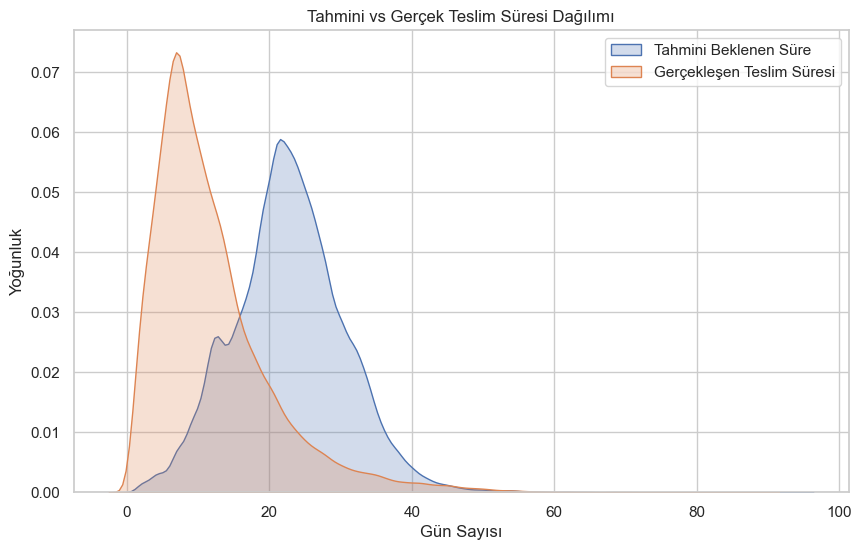

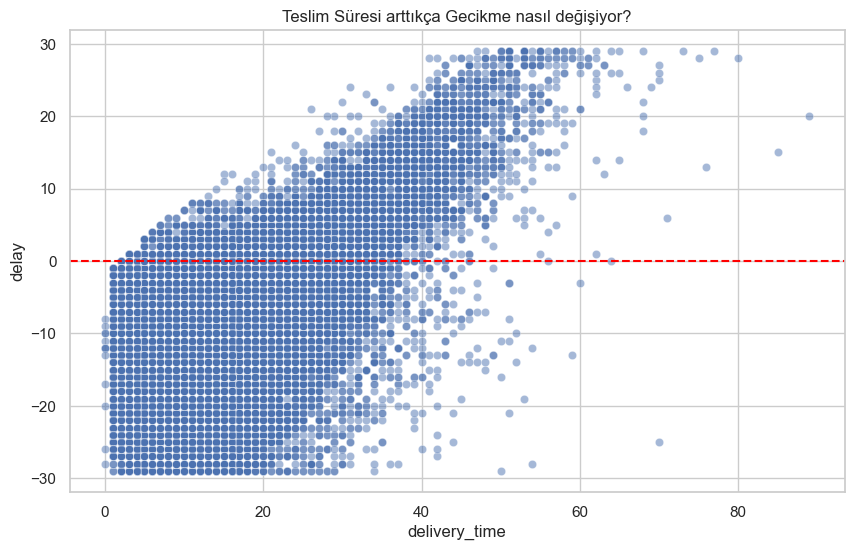

In [19]:
#  KDE Plot: Tahmini vs Gerçek
plt.figure(figsize=(10,6))
sns.kdeplot(orders_clean['estimated_delivery_days'], label='Tahmini Beklenen Süre', fill=True)
sns.kdeplot(orders_clean['delivery_time'], label='Gerçekleşen Teslim Süresi', fill=True)
plt.xlabel("Gün Sayısı")
plt.ylabel("Yoğunluk")
plt.title("Tahmini vs Gerçek Teslim Süresi Dağılımı")
plt.legend()
plt.show()

# Scatter Plot: Teslim Süresi vs Gecikme
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=orders_clean, 
    x="delivery_time", 
    y="delay",
    alpha=0.5 # Noktalar üst üste bindiğinde yoğunluğu görebilmek için
)
plt.axhline(0, color='red', linestyle='--') # 0 çizgisi (Gecikme sınırı)
plt.title("Teslim Süresi arttıkça Gecikme nasıl değişiyor?")
plt.show()

Scatter plot analizi : delay=0 bize siparişlerin büyük çoğunluğunun vaktinden önce teslim edildiğini gösteriyor. Ancak delivery_time  noktaların kırmızı çizgi üstünde yogunlaşması 40 gün sonra operasyonel verimliliğin kırılmaya başladığını gösterir.
KDE Dağılım anlaizi : Burada ise kargoların tahmin süresi uzun tutulup genelde tahminde önce teslim edildiğini görüyoruz.

In [20]:
 orders["order_day"] = orders["order_purchase_timestamp"].dt.dayofweek

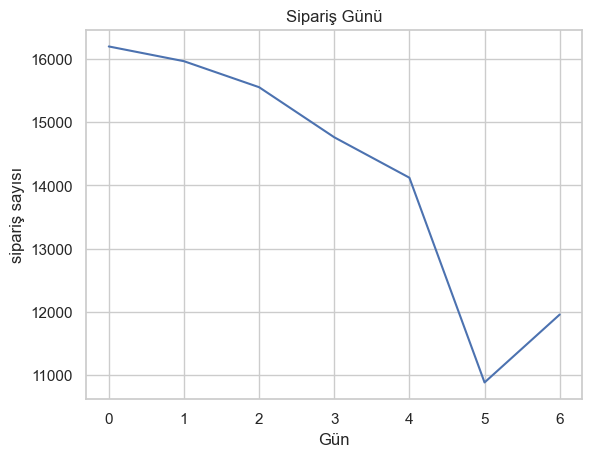

In [21]:
#Siparişlerin günlere göre teslim süreleri 
orders["order_purchase_timestamp"].dt.dayofweek.value_counts().sort_index().plot()
plt.title("Sipariş Günü")
plt.xlabel("Gün")
plt.ylabel("sipariş sayısı")
plt.show()
          


Müşterilerin alışveriş iştahı hafta başında zirve yaparken, hafta sonuna doğru dramatik bir düşüş yaşıyor. Özellikle 5. gün (Cumartesi) siparişlerin en dip yaptığı nokta.İnsanlar iş başındayken (Pazartesi-Salı) daha fazla online alışveriş yapma eğiliminde. Hafta sonu yaklaştıkça dijital harcamalar azalıyor. Pazarlama bütçesini ve bildirimleri hafta başındaki bu yoğunluğa göre optimize etmek satışları daha da artırabilir.

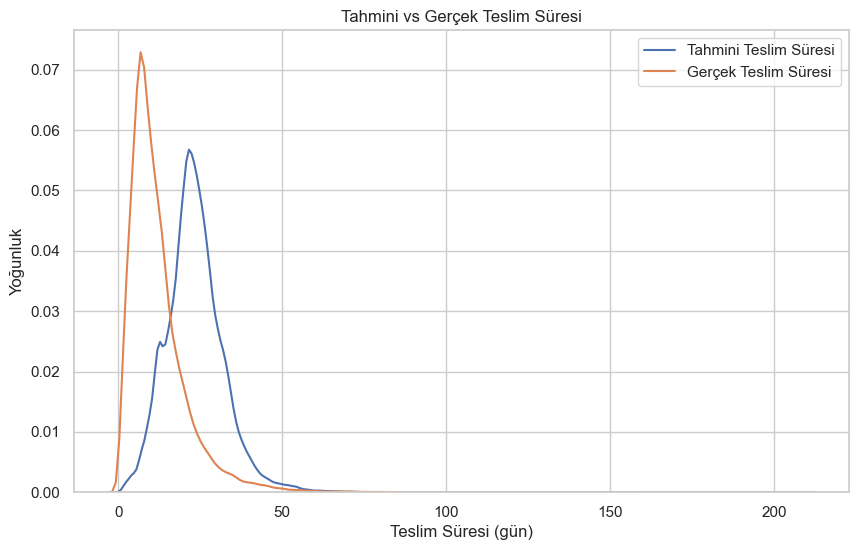

NameError: name 'orders_delivered' is not defined

In [20]:
# Teslim sürelerini gün cinsine çevir
orders['estimated_delivery_days'] = (pd.to_datetime(orders['order_estimated_delivery_date']) - pd.to_datetime(orders['order_purchase_timestamp'])).dt.days
orders['actual_delivery_days'] = (pd.to_datetime(orders['order_delivered_customer_date']) - pd.to_datetime(orders['order_purchase_timestamp'])).dt.days

plt.figure(figsize=(10,6))
sns.kdeplot(orders['estimated_delivery_days'], label='Tahmini Teslim Süresi')
sns.kdeplot(orders['actual_delivery_days'], label='Gerçek Teslim Süresi')
plt.xlabel("Teslim Süresi (gün)")
plt.ylabel("Yoğunluk")
plt.title("Tahmini vs Gerçek Teslim Süresi")
plt.legend()
plt.show()
sns.scatterplot(
    data=orders_delivered,
    x="delivery_time",
    y="delay"
)
plt.title("Teslim Süresi vs Gecikme")
plt.show()

Şirketin lojistik performansı beklentilerin üzerinde. ilk grafikte gerçek teslim süresi, tahmini süreden çok daha önce (solda) zirve yapmış.
Müşterilere verilen teslimat sözleri oldukça "temkinli" tutuluyor. Bu durum, paketlerin söylenenden daha erken ulaşmasını sağlayarak müşteri memnuniyetini olumlu yönde etkiler. Dağılımın darlığı, operasyonun belirli bir standartta ve tutarlı işlediğini gösteriyor.

ikinci grafiğin alt kısmındaki noktalar, ürünlerin tahmin edilen süreden çok daha erken teslim edildiğini gösteriyor. Ancak sağ üstteki 150-200 gün bandındaki noktalar, operasyonel olarak incelenmesi gereken ciddi kriz anlarını (kayıp kargo, gümrük takılması vb.) temsil ediyor.



In [ ]:
quick_overview(reviews,"reviews")

In [ ]:
reviews.duplicated().sum()

Yorumların çoğu metinsiz yani kullanıcılar genelde puan veriyor.Tarih kolonları string ,datetime dönüştürülmeli. Memnuniyet analizi, orders ile join yapılarak teslim süresi vs review score gibi analizler yapılabilir.

In [21]:
#Tarih verileri,*datetime* formatına çevrildi.  
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'])
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'])

In [22]:
quick_overview(order_items,"order_items")

--- ORDER_ITEMS ---


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14
5,00048cc3ae777c65dbb7d2a0634bc1ea,1,ef92defde845ab8450f9d70c526ef70f,6426d21aca402a131fc0a5d0960a3c90,2017-05-23 03:55:27,21.90,12.69
6,00054e8431b9d7675808bcb819fb4a32,1,8d4f2bb7e93e6710a28f34fa83ee7d28,7040e82f899a04d1b434b795a43b4617,2017-12-14 12:10:31,19.90,11.85
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,2018-07-10 12:30:45,810.00,70.75
8,0005a1a1728c9d785b8e2b08b904576c,1,310ae3c140ff94b03219ad0adc3c778f,a416b6a846a11724393025641d4edd5e,2018-03-26 18:31:29,145.95,11.65
9,0005f50442cb953dcd1d21e1fb923495,1,4535b0e1091c278dfd193e5a1d63b39f,ba143b05f0110f0dc71ad71b4466ce92,2018-07-06 14:10:56,53.99,11.40


(112650, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [23]:
order_items.duplicated().sum()

0

Orders (99k) > Order_items (112k) bazı siparişlerde birden fazla ürün var. Analiz yapılırken buna dikkat etmeliyiz.Aynı order_id birden fazla satır olabilir. Bu dataset, revenue hesaplama , ürün/satıcı performansı ve basket analizi için kritik.

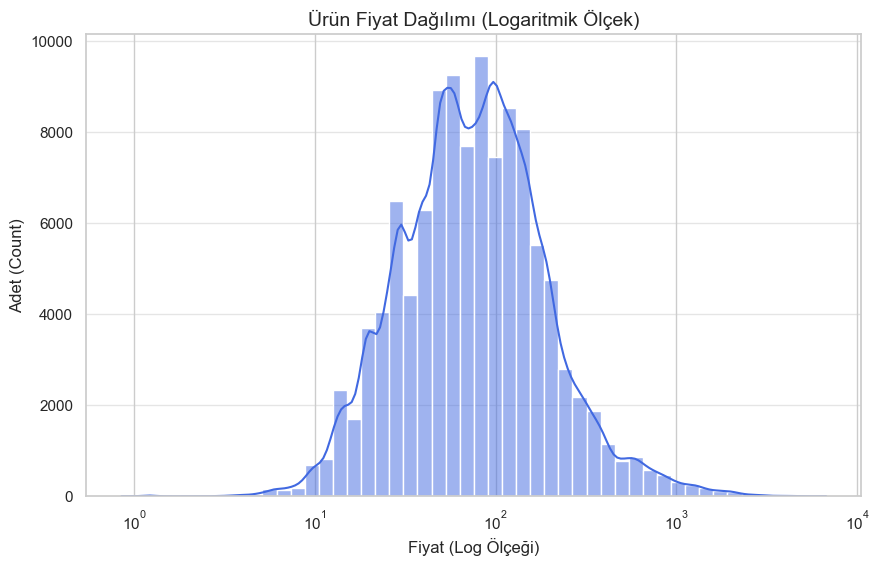

In [24]:

plt.figure(figsize=(10, 6))
sns.histplot(data=order_items, x='price', kde=True, bins=50, log_scale=True, color='royalblue')

plt.title('Ürün Fiyat Dağılımı (Logaritmik Ölçek)', fontsize=14)
plt.xlabel('Fiyat (Log Ölçeği)', fontsize=12)
plt.ylabel('Adet (Count)', fontsize=12)
plt.grid(axis='y', alpha=0.5)
plt.show()

Veri logaritmik ölçekte "Normal Dağılım"a yaklaşmış; bu da satışların büyük bir kısmının 10 ile 100 birim fiyat aralığında yoğunlaştığını, 
yani platformun orta-düşük segment ürünlerde çok güçlü olduğunu gösteriyor.Çift tepeli (bimodal) yapıya yakın görünüm, farklı iki ana ürün kategorisinin (bed_bath_table ve furniture_decor) baskın olduğunu işaret ediyor..

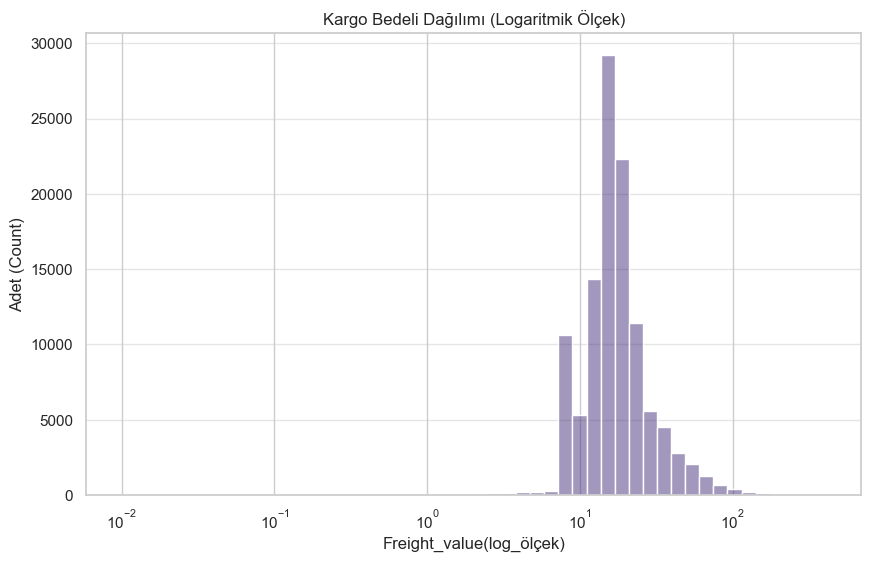

In [25]:
# Kargo bedeli dağılımı
sns.set_palette("viridis")
plt.figure(figsize=(10,6))
sns.histplot(data = order_items, x = 'freight_value', bins=50, kde=True, log_scale = True,)
plt.title("Kargo Bedeli Dağılımı (Logaritmik Ölçek)")
plt.xlabel("Freight_value(log_ölçek)", fontsize=12 )
plt.ylabel('Adet (Count)', fontsize=12)
plt.grid(axis='y', alpha=0.5)
plt.show()


 Kargo ücretleri çok dar bir aralıkta $10^1$ civarı, yani 10-20 birim inanılmaz yüksek bir yığılma gösteriyor; 
bu da platformda standart bir kargo fiyatlandırması veya lojistik anlaşmasının hakim olduğunu kanıtlıyor.

In [26]:
quick_overview(products,"products")

--- PRODUCTS ---


,,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumery,40.00,287.00,1.00,225.00,16.00,10.00,14.00
1,3aa071139cb16b67ca9e5dea641aaa2f,arts,44.00,276.00,1.00,1000.00,30.00,18.00,20.00
2,96bd76ec8810374ed1b65e291975717f,sports_leisure,46.00,250.00,1.00,154.00,18.00,9.00,15.00
3,cef67bcfe19066a932b7673e239eb23d,baby,27.00,261.00,1.00,371.00,26.00,4.00,26.00
4,9dc1a7de274444849c219cff195d0b71,housewares,37.00,402.00,4.00,625.00,20.00,17.00,13.00
5,41d3672d4792049fa1779bb35283ed13,musical_instruments,60.00,745.00,1.00,200.00,38.00,5.00,11.00
6,732bd381ad09e530fe0a5f457d81becb,cool_stuff,56.00,1272.00,4.00,18350.00,70.00,24.00,44.00
7,2548af3e6e77a690cf3eb6368e9ab61e,furniture_decor,56.00,184.00,2.00,900.00,40.00,8.00,40.00
8,37cc742be07708b53a98702e77a21a02,home_appliances,57.00,163.00,1.00,400.00,27.00,13.00,17.00
9,8c92109888e8cdf9d66dc7e463025574,toys,36.00,1156.00,1.00,600.00,17.00,10.00,12.00


(32951, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0                               32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [27]:
products.duplicated().sum()

0

Ürünlere ait kategori, içerik ve fiziksel özellik bilgilerini içeriyor. 
Her ürün için isim/açıklama uzunluğu, fotoğraf sayısı, ağırlık ve boyutlar bulunuyor.  
Bu veri seti ile ürün performansı, kategori analizi ve lojistik  incelemeler için kullanılabilir. Analizlerde tek başına değil order_items ile join edilerek kullanılmalı.

In [28]:
products.rename(columns={products.columns[0]:'product_id'},inplace=True) # product_id sütunu adlandırması yapıldı

In [29]:
products = products.dropna(subset=['product_category_name'])

 Products veri setinde `product_category_name` sütununda 610 eksik değer (NaN) bulundu.  
Bu satırlar analiz ve modelleme için değer taşımıyor çünkü: kategori, açıklama ve fotoğraf girilmemiş.
Bu nedenle,bu düşük kaliteli kayıtlar temizlendi.

In [30]:
products['product_category_name'].value_counts().head(20)

product_category_name
bed_bath_table                     3029
sports_leisure                     2867
furniture_decor                    2657
healty_beauty                      2444
housewares                         2335
auto                               1900
computers_accessories              1639
toys                               1411
watches_gifts                      1329
telephony                          1134
baby                                919
perfumery                           868
stationery                          849
fashion_bags_accessories            849
cool_stuff                          789
garden_tools                        753
pet_shop                            719
electronics                         517
construction_tools_construction     400
home_appliances                     370
Name: count, dtype: int64

In [31]:
#Kategori adları çevrildi ve standartlaştırıldı.Tutarsızlıklar tespit edilip düzeltildi.
products['product_category_name'] = products['product_category_name'].replace({
    'healty_beauty': 'healthy_beauty',
    'costruction_tools_tools': 'construction_tools_tools',
    'home_confort': 'home_comfort',
    'home_confort_2': 'home_comfort_2',
    'arts_and_craftmanship': 'arts_and_craftsmanship',
    'cds_dvds_musicis': 'cds_dvds_music'
})

In [32]:
products.head()  #products veri seti düzenlenmiş hali.

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumery,40.00,287.00,1.00,225.00,16.00,10.00,14.00
1,3aa071139cb16b67ca9e5dea641aaa2f,arts,44.00,276.00,1.00,1000.00,30.00,18.00,20.00
2,96bd76ec8810374ed1b65e291975717f,sports_leisure,46.00,250.00,1.00,154.00,18.00,9.00,15.00
3,cef67bcfe19066a932b7673e239eb23d,baby,27.00,261.00,1.00,371.00,26.00,4.00,26.00
4,9dc1a7de274444849c219cff195d0b71,housewares,37.00,402.00,4.00,625.00,20.00,17.00,13.00


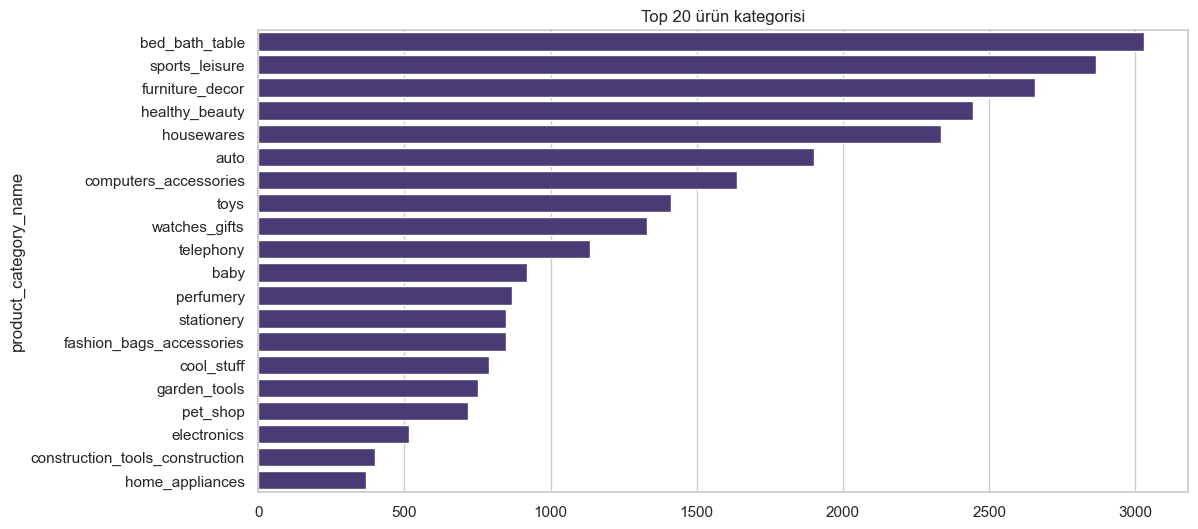

In [33]:
# Ürün kategorilerine göre sayılar
plt.figure(figsize=(12,6))

top_categories = products['product_category_name'].value_counts().head(20)

sns.barplot(
    x=top_categories.values, 
    y=top_categories.index
)

plt.title("Top 20 ürün kategorisi")
plt.show()

Pazarın dinamosu: "bed_bath_table" (Ev Tekstili), "sports_leisure" ve "furniture_decor" kategorileri, platformun ana gelir ve trafik kaynağını oluşturuyor.İlk sıralardaki ürünlerin ev yaşamı, kişisel bakım ve hobi odaklı olması, müşterilerin bu platformu daha çok günlük yaşam konforu ve kişisel ihtiyaçlar için tercih ettiğini gösteriyor.İlk 5-6 kategori toplam hacmin çok büyük bir kısmını kapladığı için, stok yönetimi ve kampanya önceliklerinin bu alanlara verilmesi operasyonel verimliliği maksimize edecektir.

In [34]:
items_with_products = order_items.merge(
    products[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

In [35]:
df_final = orders.merge(items_with_products, on='order_id', how='left')

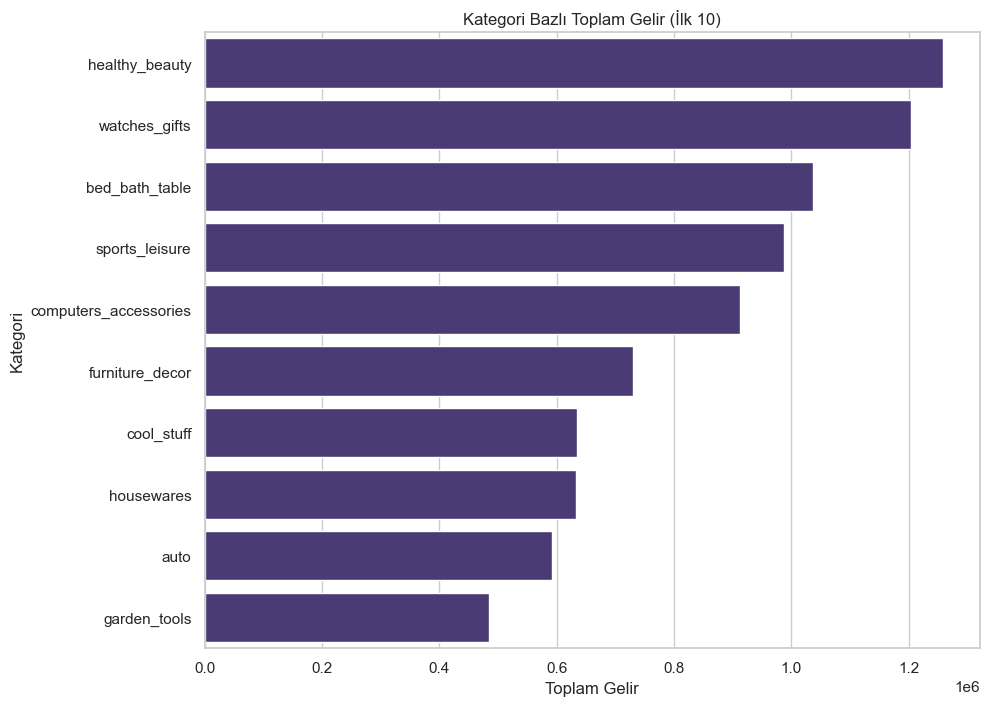

In [36]:
category_revenue = (
    items_with_products
    .groupby('product_category_name')['price']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Sadece ilk 10 kategori
top10_categories = category_revenue.head(10)

plt.figure(figsize=(10, 8))
sns.barplot(
    x='price',
    y='product_category_name',
    data=top10_categories
)

plt.title("Kategori Bazlı Toplam Gelir (İlk 10)")
plt.xlabel("Toplam Gelir")
plt.ylabel("Kategori")
plt.show()

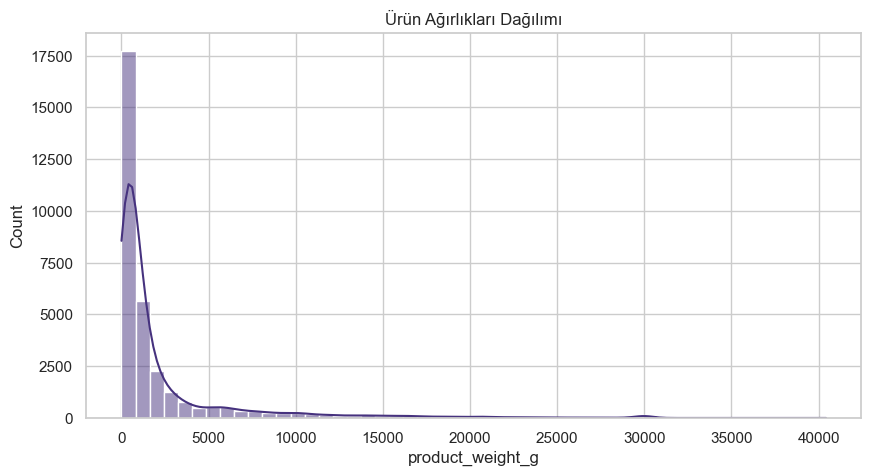

In [37]:
# Ürün ağırlık dağılımı
plt.figure(figsize=(10,5))
sns.histplot(products['product_weight_g'], bins=50, kde=True)
plt.title("Ürün Ağırlıkları Dağılımı")
plt.show()

Ürünlerin ezici bir çoğunluğu 0-5 kg (5000g) aralığında yoğunlaşmış durumda. Bu, platformun kargo maliyetleri açısından avantajlı olan hafif ve taşınabilir ürünler (kozmetik, küçük aksesuarlar, ev tekstili) üzerine kurulu olduğunu gösteriyor.

In [38]:
quick_overview(payments,"payments")

--- PAYMENTS ---


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45
5,298fcdf1f73eb413e4d26d01b25bc1cd,1,credit_card,2,96.12
6,771ee386b001f06208a7419e4fc1bbd7,1,credit_card,1,81.16
7,3d7239c394a212faae122962df514ac7,1,credit_card,3,51.84
8,1f78449c87a54faf9e96e88ba1491fa9,1,credit_card,6,341.09
9,0573b5e23cbd798006520e1d5b4c6714,1,boleto,1,51.95


(103886, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


Orders (99k) < Payments (103k)
bazı siparişlerde birden fazla ödeme işlemi vardır.Bu tablo siparişlere ait ödeme bilgilerini içerir.Her sipariş için ödeme tipi, taksit sayısı ve toplam ödeme tutarı yer alıyor.Aynı sipariş için birden fazla satır olabilir ,yani Aynı order_id birden fazla satır içerebilir.Aggregation dikkatli yapılmalı.

In [39]:
payments.duplicated().sum()

0

In [40]:
# order_id bazında aggregate,
payment_agg = payments.groupby("order_id").agg({
    "payment_value": "sum",           # toplam ödeme
    "payment_installments": "mean"    # ortalama taksit sayısı
}).reset_index()


In [41]:
# df_orders ile merge
df_orders = orders.copy() 
df_orders = df_orders.merge(payment_agg, on="order_id", how="left")


In [42]:
# kolon isimlendirmeleri
df_orders.rename(columns={
    "payment_value": "total_payment",
    "payment_installments": "avg_installments"
}, inplace=True)

In [43]:
df_orders.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,year,delay,delivery_time,order_day,estimated_delivery_days,actual_delivery_days,total_payment,avg_installments
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,-8.00,8.00,0,15,8.00,38.71,1.00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,-6.00,13.00,1,19,13.00,141.46,1.00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,-18.00,9.00,2,26,9.00,179.12,3.00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,-13.00,13.00,5,26,13.00,72.20,1.00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,-10.00,2.00,1,12,2.00,28.62,1.00


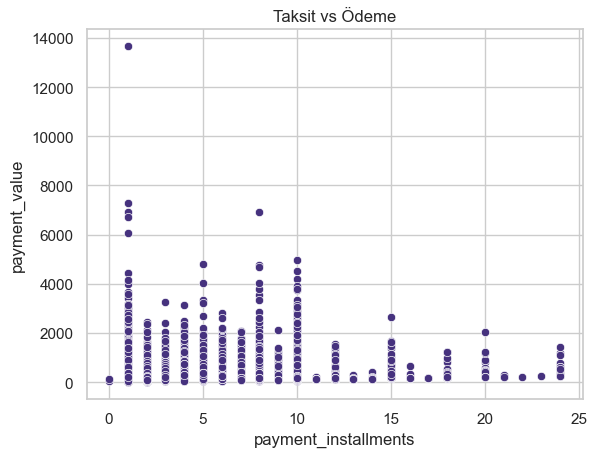

In [44]:
sns.scatterplot(
    x="payment_installments",
    y="payment_value",
    data=payments
)
plt.title("Taksit vs Ödeme")
plt.show()

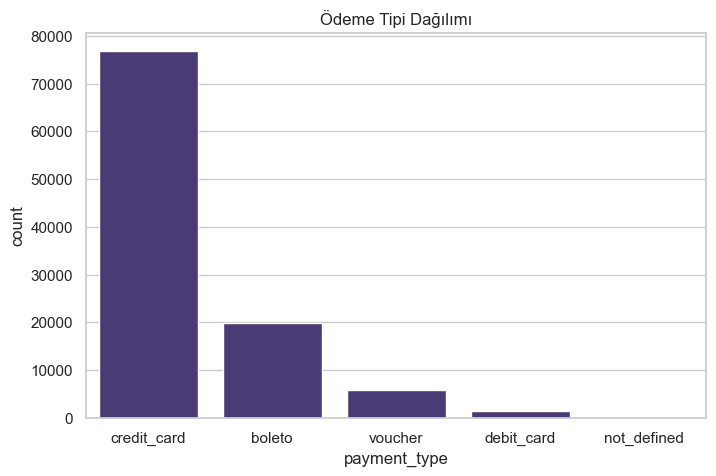

In [45]:
# Ödeme tiplerinin dağılımı
plt.figure(figsize=(8,5))
sns.countplot(data=payments, x='payment_type', order=payments['payment_type'].value_counts().index)
plt.title("Ödeme Tipi Dağılımı")
plt.show()

Kredi kartı açık ara en popüler ödeme yöntemi.Bu durum müşterilerin taksitlendirme veya erteleme gibi kredi kartı avantajlarından faydalandığını gösterir. Brezilya'ya özgü 'boleto' ise ikinci sırada , banka kartıyla ödeme şekli ise ciddi oranda düşük. Pazarlama stratejilerinde kredi kartı kullanıcılarına yönelik kampanyalara ağırlık verilebilir. 

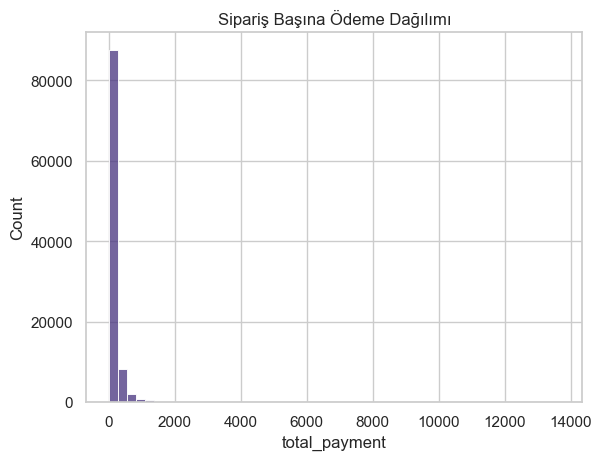

In [46]:
sns.histplot(df_orders["total_payment"], bins=50)
plt.title("Sipariş Başına Ödeme Dağılımı")
plt.show()

Siparişlerin büyük çoğunluğu düşük değerli, ancak gelir az sayıda yüksek değerli siparişten geliyor
Taksit kullanımı özellikle yüksek tutarlı alışverişlerde yoğunlaşıyor
Bu da taksit mekanizmasının satış artırıcı bir kaldıraç olduğunu gösteriyor

In [47]:
df_orders.sort_values("total_payment", ascending=False).head(20)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,year,delay,delivery_time,order_day,estimated_delivery_days,actual_delivery_days,total_payment,avg_installments
13390,03caa2c082116e1d31e67e9ae3700499,1617b1357756262bfa56ab541c47bc16,delivered,2017-09-29 15:24:52,2017-10-02 15:28:20,2017-10-10 15:43:17,2017-10-17 18:22:29,2017-10-23,2017,-6.00,18.00,4,23,18.00,13664.08,1.00
66599,736e1922ae60d0d6a89247b851902527,ec5b2ba62e574342386871631fafd3fc,delivered,2018-07-15 14:49:44,2018-07-17 04:31:36,2018-07-20 13:09:00,2018-07-26 22:03:06,2018-08-02,2018,-7.00,11.00,6,17,11.00,7274.88,1.00
22171,0812eb902a67711a1cb742b3cdaa65ae,c6e2731c5b391845f6800c97401a43a9,delivered,2017-02-12 20:37:36,2017-02-12 20:45:12,2017-02-16 09:23:13,2017-03-03 14:23:18,2017-03-09,2017,-6.00,18.00,6,24,18.00,6929.31,8.00
28326,fefacc66af859508bf1a7934eab1e97f,f48d464a0baaea338cb25f816991ab1f,delivered,2018-07-25 18:10:17,2018-07-27 04:05:13,2018-08-03 14:42:00,2018-08-15 14:57:50,2018-08-10,2018,5.00,20.00,2,15,20.00,6922.21,1.00
3508,f5136e38d1a14a4dbd87dff67da82701,3fd6777bbce08a352fddd04e4a7cc8f6,delivered,2017-05-24 18:14:34,2017-05-26 02:45:17,2017-05-26 11:20:47,2017-06-05 17:09:48,2017-06-28,2017,-23.00,11.00,2,34,11.00,6726.66,1.00
32322,2cc9089445046817a7539d90805e6e5a,05455dfa7cd02f13d132aa7a6a9729c6,delivered,2017-11-24 11:03:35,2017-11-28 12:55:46,2017-12-06 11:52:14,2017-12-13 12:16:02,2017-12-22,2017,-9.00,19.00,4,27,19.00,6081.54,1.00
53352,a96610ab360d42a2e5335a3998b4718a,df55c14d1476a9a3467f131269c2477f,delivered,2017-04-01 15:58:40,2017-04-03 13:25:18,2017-04-11 15:10:34,2017-04-17 11:04:45,2017-05-02,2017,-15.00,15.00,5,30,15.00,4950.34,10.00
41086,b4c4b76c642808cbe472a32b86cddc95,e0a2412720e9ea4f26c1ac985f6a7358,canceled,2018-07-12 12:08:36,2018-07-12 12:25:53,NaN,NaT,2018-08-01,2018,NaN,NaN,3,19,NaN,4809.44,5.00
40327,199af31afc78c699f0dbf71fb178d4d4,24bbf5fd2f2e1b359ee7de94defc4a15,delivered,2017-04-18 18:50:13,2017-04-19 15:50:15,2017-04-25 13:39:59,2017-05-07 10:42:39,2017-05-15,2017,-8.00,18.00,1,26,18.00,4764.34,8.00
40342,8dbc85d1447242f3b127dda390d56e19,3d979689f636322c62418b6346b1c6d2,delivered,2018-06-22 12:23:19,2018-06-22 12:36:36,2018-06-22 13:00:00,2018-07-06 01:08:30,2018-07-17,2018,-11.00,13.00,4,24,13.00,4681.78,8.00


In [48]:
quick_overview(sellers,"sellers")

--- SELLERS ---


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP
5,c240c4061717ac1806ae6ee72be3533b,20920,rio de janeiro,RJ
6,e49c26c3edfa46d227d5121a6b6e4d37,55325,brejao,PE
7,1b938a7ec6ac5061a66a3766e0e75f90,16304,penapolis,SP
8,768a86e36ad6aae3d03ee3c6433d61df,1529,sao paulo,SP
9,ccc4bbb5f32a6ab2b7066a4130f114e3,80310,curitiba,PR


(3095, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [49]:
sellers.duplicated().sum()

0

Dataset çok kompakt, her satıcı bir satır.Coğrafi dağılım analiz edilebilir: şehir ve eyalet bazlı
Posta kodu, satıcı ile müşteri veya lojistik analizinde kullanılabilir.

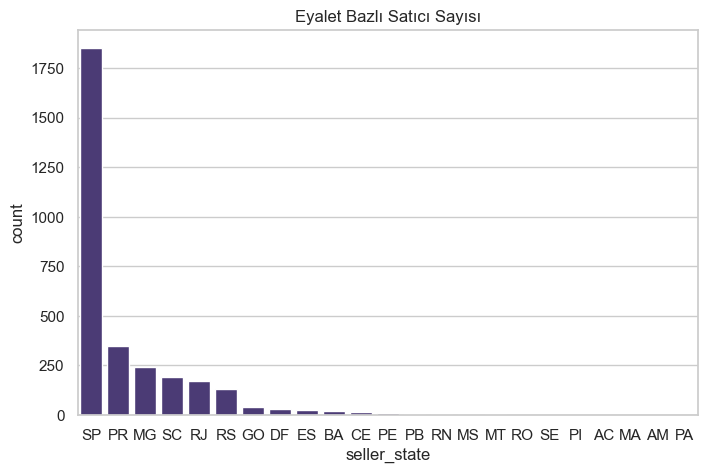

In [50]:
# Eyalet bazlı satıcı sayısı
plt.figure(figsize=(8,5))
sns.countplot(data=sellers, x='seller_state', order=sellers['seller_state'].value_counts().index)
plt.title("Eyalet Bazlı Satıcı Sayısı")
plt.show()

Satıcı dağılımı, müşteri dağılımından bile daha uç bir dengesizliğe sahip. SP (Sao Paulo) eyaleti, satıcıların ana merkezi konumunda ve diğer tüm eyaletlere devasa bir fark atmış durumda.Ticaretin kalbi Sao Paulo'da atıyor. Bu durum, çoğu ürünün buradan yola çıktığını ve lojistik merkezlerin neden bu bölgede kümelendiğini net bir şekilde açıklıyor.

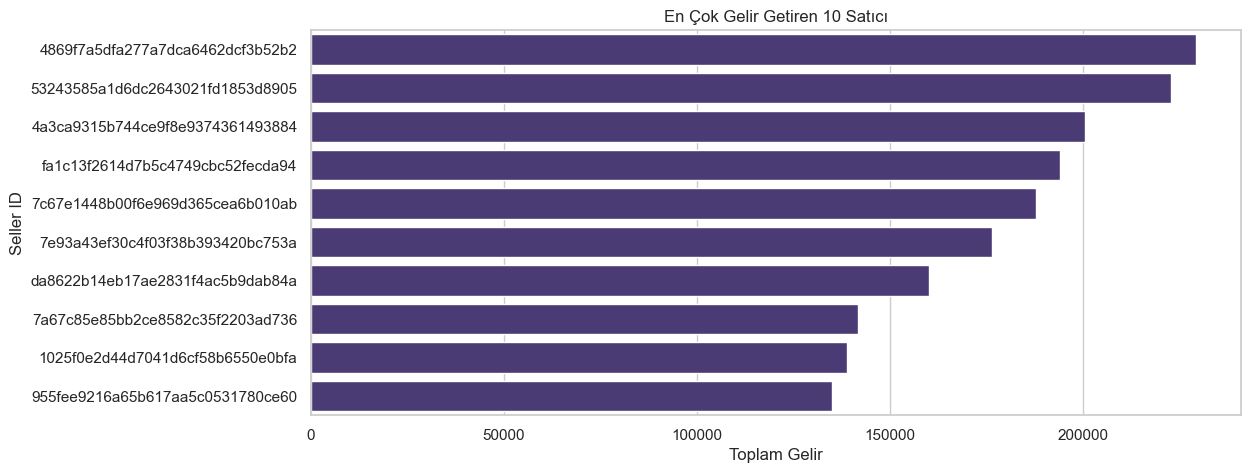

In [51]:
seller_performance = order_items.groupby('seller_id')['price'].sum().reset_index()
top_sellers = seller_performance.sort_values('price', ascending=False).head(10)
worst_sellers = seller_performance.sort_values('price', ascending=True).head(10)

plt.figure(figsize=(12,5))
sns.barplot(x='price', y='seller_id', data=top_sellers)
plt.title("En Çok Gelir Getiren 10 Satıcı")
plt.xlabel("Toplam Gelir")
plt.ylabel("Seller ID")
plt.show()

In [52]:
quick_overview(geolocation,"geolocation")

--- GEOLOCATION ---


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP
3,1041,-23.54,-46.64,sao paulo,SP
4,1035,-23.54,-46.64,sao paulo,SP
5,1012,-23.55,-46.64,são paulo,SP
6,1047,-23.55,-46.64,sao paulo,SP
7,1013,-23.55,-46.63,sao paulo,SP
8,1029,-23.54,-46.63,sao paulo,SP
9,1011,-23.55,-46.64,sao paulo,SP


(1000163, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


Bir zip code da birden fazla koordinat var. Bu nedenle veri seti aggregated edilmeli.
city ve state kolonları ile coğrafi analiz yapılabilir. customers ve sellers ile joinlenebilir.

In [53]:
geolocation.duplicated(subset=['geolocation_zip_code_prefix']).sum()

981148

In [54]:
geolocation['geolocation_zip_code_prefix'].nunique()

19015

In [55]:
geo_clean = geolocation.groupby('geolocation_zip_code_prefix').agg({
    'geolocation_lat': 'median',
    'geolocation_lng': 'median'
}).reset_index()   ## Zip code başına tek ve outlier'a dayanıklı koordinat elde etmek için median ile aggregation

In [56]:
geo_clean.duplicated().sum()

0

In [57]:
geo_clean.shape

(19015, 3)

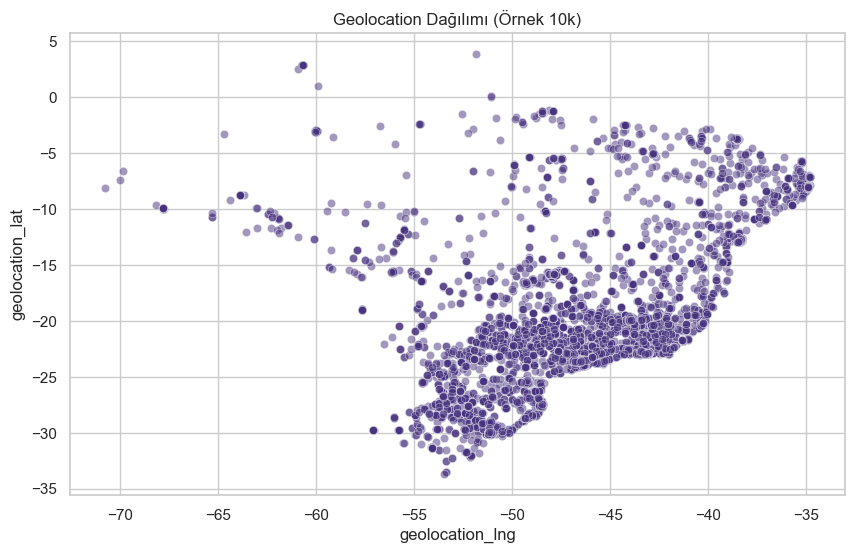

In [58]:
# Lat ve Lng dağılımı (çok nokta olduğu için örnek alıyoruz)
plt.figure(figsize=(10,6))
sample_geo = geolocation.sample(10000)  # 10k örnek
sns.scatterplot(x='geolocation_lng', y='geolocation_lat', data=sample_geo, alpha=0.5)
plt.title("Geolocation Dağılımı (Örnek 10k)")
plt.show()

 Noktaların en yoğun olduğu sağ alt bölge (Güneydoğu ve Güney sahilleri), ülkenin en gelişmiş ve nüfusu en yoğun olan bölgelerine tam olarak karşılık geliyor. Kuzey ve iç kısımlardaki boşluklar, o bölgelerde internet alışverişinin veya teslimat ağının henüz seyrek olduğunu; ticaretin ise kıyı şeridinde ve sanayileşmiş eyaletlerde hapsolduğunu gösteriyor.
Firma lojistik olarak şanslı( ya da iyi planlanmış) çünkü ürünleri hafif günlük yaşam ürünleri ve satıcılar tek bir bölgede toplanmış. Bu, depolama ve toplu kargo anlaşmaları için büyük bir avantaj.

# Final dataset 

In [69]:
# Ödemeler sipariş bazında toplanır.
payment_agg = payments.groupby("order_id").agg({
    "payment_value": "sum",
    "payment_installments": "mean"
}).reset_index().rename(columns={"payment_value": "total_order_payment", "payment_installments": "avg_installments"})

# Ürün, Kategori ve Satıcı bilgileri(Detaylı Ürün Tablosu)
items_detailed = order_items.merge(products, on='product_id', how='left') \
                            .merge(sellers, on='seller_id', how='left')

# Orders ana tablomuz
df_final = orders.merge(items_detailed, on='order_id', how='left') \
                 .merge(customers, on='customer_id', how='left') \
                 .merge(payment_agg, on='order_id', how='left') \
                 .merge(reviews[['order_id', 'review_score']], on='order_id', how='left') \
                 .merge(geo_clean, left_on='customer_zip_code_prefix', right_on='geolocation_zip_code_prefix', how='left')

#Temizlik ve Kolon İsimlendirme
df_final.rename(columns={
    'geolocation_lat': 'customer_lat',
    'geolocation_lng': 'customer_lng'
}, inplace=True)

# Kalabalık yapan prefix kolonunu kaldırdık
if 'geolocation_zip_code_prefix' in df_final.columns:
    df_final.drop(columns=['geolocation_zip_code_prefix'], inplace=True)

#Feature Engineering (Tarihsel Hesaplamalar)
df_final['order_purchase_timestamp'] = pd.to_datetime(df_final['order_purchase_timestamp'])
df_final['delivery_time'] = (pd.to_datetime(df_final['order_delivered_customer_date']) - df_final['order_purchase_timestamp']).dt.days
df_final['delay'] = (pd.to_datetime(df_final['order_delivered_customer_date']) - pd.to_datetime(df_final['order_estimated_delivery_date'])).dt.days


In [70]:
#Feature Engineering (Tarihsel Hesaplamalar)
df_final['order_purchase_timestamp'] = pd.to_datetime(df_final['order_purchase_timestamp'])
df_final['delivery_time'] = (pd.to_datetime(df_final['order_delivered_customer_date']) - df_final['order_purchase_timestamp']).dt.days
df_final['delay'] = (pd.to_datetime(df_final['order_delivered_customer_date']) - pd.to_datetime(df_final['order_estimated_delivery_date'])).dt.days


In [71]:
if not os.path.exists("outputs"):
    os.makedirs("outputs")

df_final.to_csv("outputs/final_dataset.csv", index=False)
print(f"Final Dataset Hazır! Toplam Satır: {df_final.shape[0]}, Toplam Kolon: {df_final.shape[1]}")

Final Dataset Hazır! Toplam Satır: 114092, Toplam Kolon: 40


In [72]:
df_final.head(10)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,year,delay,delivery_time,order_day,estimated_delivery_days,actual_delivery_days,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,seller_zip_code_prefix,seller_city,seller_state,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,total_order_payment,avg_installments,review_score,customer_lat,customer_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,2017,-8.00,8.00,0,15,8.00,1.00,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,housewares,40.00,268.00,4.00,500.00,19.00,8.00,13.00,9350.00,maua,SP,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,38.71,1.00,4.00,-23.58,-46.59
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,2018,-6.00,13.00,1,19,13.00,1.00,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumery,29.00,178.00,1.00,400.00,19.00,13.00,19.00,31570.00,belo horizonte,SP,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,141.46,1.00,4.00,-12.13,-45.01
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,2018,-18.00,9.00,2,26,9.00,1.00,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,auto,46.00,232.00,1.00,420.00,24.00,19.00,21.00,14840.00,guariba,SP,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,179.12,3.00,5.00,-16.74,-48.51
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,2017,-13.00,13.00,5,26,13.00,1.00,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,59.00,468.00,3.00,450.00,30.00,10.00,20.00,31842.00,belo horizonte,MG,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,72.20,1.00,5.00,-5.77,-35.27
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2018,-10.00,2.00,1,12,2.00,1.00,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,stationery,38.00,316.00,4.00,250.00,51.00,15.00,15.00,8752.00,mogi das cruzes,SP,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,28.62,1.00,5.00,-23.68,-46.52
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,2017-07-09 21:57:05,2017-07-09 22:10:13,2017-07-11 14:58:04,2017-07-26 10:57:55,2017-08-01,2017,-6.00,16.00,6,22,16.00,1.00,060cb19345d90064d1015407193c233d,8581055ce74af1daba164fdbd55a40de,2017-07-13 22:10:13,147.90,27.36,auto,49.00,608.00,1.00,7150.00,65.00,10.00,65.00,7112.00,guarulhos,SP,80bb27c7c16e8f973207a5086ab329e2,86320,congonhinhas,PR,175.26,6.00,4.00,-23.55,-50.55
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaN,NaT,2017-05-09,2017,NaN,NaN,1,27,NaN,1.00,a1804276d9941ac0733cfd409f5206eb,dc8798cbf453b7e0f98745e396cc5616,2017-04-19 13:25:17,49.90,16.05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5455.00,sao paulo,SP,36edbb3fb164b1f16485364b6fb04c73,98900,santa rosa,RS,65.95,1.00,2.00,-27.87,-54.47
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07,

In [73]:
df_final.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'year', 'delay', 'delivery_time', 'order_day',
       'estimated_delivery_days', 'actual_delivery_days', 'order_item_id',
       'product_id', 'seller_id', 'shipping_limit_date', 'price',
       'freight_value', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'seller_zip_code_prefix', 'seller_city', 'seller_state',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'total_order_payment', 'avg_installments',
       'review_score', 'customer_lat', 'customer_lng'],
      dtype='object')

# SQL analizi için dataset hazırlığı

In [74]:
!pip install psycopg2-binary

In [81]:
import os
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

# 1. .env dosyasını zorlayarak yükle
load_dotenv(override=True)

db_user = os.getenv("DB_USER")
db_password = os.getenv("DB_PASSWORD")
db_host = os.getenv("DB_HOST")
db_port = os.getenv("DB_PORT")
db_name = os.getenv("DB_NAME")

# 2. Veriyi oku
df_final = pd.read_csv("outputs/final_dataset.csv")

# 3. İsim temizliği (Küçük harf ve boşluk yerine alt çizgi)
df_final.columns = [c.lower().strip().replace(" ", "_") for c in df_final.columns]

# 4. Bağlantı dizesi ve Engine
conn_str = f'postgresql://{db_user}:{db_password}@{db_host}:{db_port}/{db_name}'
engine = create_engine(conn_str)

# 5. YÜKLEME
table_name = 'olist_master'
schema_name = 'olist_project' 

try:
    print(f"{table_name} tablosu {db_host}:{db_port} adresine yükleniyor...")
    df_final.to_sql(table_name, 
                    con=engine, 
                    schema=schema_name, 
                    if_exists='replace', 
                    index=False, 
                    chunksize=10000)
    print("Yükleme başarıyla tamamlandı!")
except Exception as e:
    print(f"Hata: {e}")

olist_master tablosu localhost:5433 adresine yükleniyor...
Yükleme başarıyla tamamlandı!


# Stratejik Veri Analizi Özeti

#### Operasyonel Verimlilik ve Lojistik Başarı 

Veriler, şirketin lojistik vaatlerini yerine getirme konusunda oldukça başarılı olduğunu kanıtlıyor.
Gerçek teslimat sürelerinin tahmini sürelerden çok daha kısa olması, müşteri memnuniyeti için güçlü bir temel oluşturuyor.
Operasyonun kalbi olan Sao Paulo, hem satıcı hem de müşteri yoğunluğuyla ticaretin merkezi konumunda.
Ancak coğrafi dağılım (Scatter plot), iç bölgelere yayılımın kısıtlı olduğunu ve buraların potansiyel bir büyüme alanı olduğunu gösteriyor.

#### Ürün ve Pazar Dinamikleri

Platform, temel olarak orta-düşük segment ürünlerin (10-100 birim fiyat aralığı) ve hafif paketlerin (0-5 kg) yüksek hacimle döndüğü bir pazar yeri profili çiziyor. 
"Bed & Bath" ve "Health & Beauty" gibi kategoriler sürümden kazandırırken; mobilya ve dekorasyon gibi daha yüksek fiyatlı kategoriler ikinci bir gelir dalgası yaratıyor.

#### Tüketici Davranışı ve Satış Kanalları

Müşteriler, tekil ürün odaklı bir alışveriş alışkanlığına sahip (sipariş başına 1 ürün) ve ödemelerini ezici bir çoğunlukla kredi kartı ile yapmayı tercih ediyor. Satışların hafta başındaki yüksek seyri ve hafta sonundaki düşüşü, dijital pazarlama bütçesinin haftalık dağılımı için kritik bir veri sunuyor. 2017 sonundaki agresif büyüme, markanın pazar dominasyonunu net bir şekilde ortaya koyuyor. Burada müşterilerin ödeme yöntemlerine yönelik kampanyalara öncelik verilerek satış hacminde büyüme yakalanabilir.

#### Temel Çıkarım :
Bu analiz, operasyonun istikrarlı ve güvenilir olduğunu (teslimat performansı), ancak kârlılığı artırmak için sipariş başına ürün sayısını (sepet ortalamasını) artıracak ve Sao Paulo dışındaki eyaletlere lojistik ağını genişletecek stratejilere ihtiyaç duyulduğunu göstermekte.